# 04 - Binning, WoE and Information Value

**Goal:** turn each predictor into a small number of **bins** (coarse classing), compute the **Weight of Evidence (WoE)** of every bin and the
**Information Value (IV)** of every variable. Everything is learned on the **development set only**; the hold-out set is not opened here.

**Definitions**
- WoE of a bin = ln(%good in bin / %bad in bin), where the percentages are taken against the totals of the whole development set.
  Negative WoE = riskier than average; positive = safer.
- IV of a variable = sum over bins of (%good - %bad) x WoE. It measures how well the variable separates good from bad.
  Conventional reading: < 0.02 useless, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong, > 0.5 suspiciously strong (check leakage).

**Binning rules (implemented in `src/feature_engineering.py`, unit-tested in `tests/`)**
1. Fine classing first (every distinct value, or ~40 quantile bins), then merge **adjacent** bins.
2. WoE must be **monotonic** in the direction given by business logic (or "free" where a U-shape is meaningful).
3. Every bin has a minimum share of the sample and at least 50 bad cases.
4. Adjacent bins must differ by at least 0.05 in WoE, and at most 8 bins are kept (the merge that loses the least IV goes first).
5. `NaN` is **not** imputed: it gets its own "Missing" bin (if it has at least 30 bad cases), otherwise it joins the numeric bin with the closest WoE.

In [1]:
import sys, json
sys.path.insert(0, "../src")

from pathlib import Path
for _p in ("../data/processed", "../outputs/figures", "../outputs/metrics", "../outputs/scorecard"):
    Path(_p).mkdir(parents=True, exist_ok=True)   # Git does not keep empty folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from feature_engineering import WoEBinner, iv_summary, iv_strength

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

dev = pd.read_csv("../data/processed/dev.csv", index_col="id")
y = dev["target"]
print("Development set:", dev.shape, "| bad rate:", round(y.mean(), 4))

Development set: (104987, 12) | bad rate: 0.0669


## 1. Binning configuration

The direction of each trend comes from **business logic**, not from the data. `min_share` is the minimum share of the development sample per bin.

In [2]:
CONFIG = {
    # variable:        (trend,             min_share, business rationale)
    "revolving_util":  ("increasing_risk", 0.02, "Higher utilization of credit limits means more financial stress. 2% keeps the over-limit group (> 100%) as its own bin"),
    "age":             ("decreasing_risk", 0.05, "Older borrowers are historically more stable"),
    "n_30_59_late":    ("increasing_risk", 0.01, "More past-due events mean higher risk. Small share allowed because most borrowers have 0"),
    "n_60_89_late":    ("increasing_risk", 0.01, "Same logic, more severe delinquency"),
    "n_90_late":       ("increasing_risk", 0.01, "Same logic, most severe delinquency"),
    "debt_ratio":      ("increasing_risk", 0.05, "Higher debt burden relative to income means higher risk"),
    "monthly_income":  ("decreasing_risk", 0.05, "Higher income means more capacity to repay"),
    "n_open_lines":    ("decreasing_risk", 0.01, "Very few open lines means a thin credit history, riskier"),
    "n_real_estate":   ("free",            0.01, "U-shape is plausible (no property vs over-leveraged), so no monotonic constraint"),
    "n_dependents":    ("increasing_risk", 0.01, "More dependents means more financial burden"),
}
pd.DataFrame(CONFIG, index=["trend", "min_share", "rationale"]).T

,trend,min_share,rationale
revolving_util,increasing_risk,0.02,Higher utilization of credit limits means more...
age,decreasing_risk,0.05,Older borrowers are historically more stable
n_30_59_late,increasing_risk,0.01,More past-due events mean higher risk. Small s...
n_60_89_late,increasing_risk,0.01,"Same logic, more severe delinquency"
n_90_late,increasing_risk,0.01,"Same logic, most severe delinquency"
debt_ratio,increasing_risk,0.05,Higher debt burden relative to income means hi...
monthly_income,decreasing_risk,0.05,Higher income means more capacity to repay
n_open_lines,decreasing_risk,0.01,Very few open lines means a thin credit histor...
n_real_estate,free,0.01,U-shape is plausible (no property vs over-leve...
n_dependents,increasing_risk,0.01,More dependents means more financial burden


## 2. Fine classing vs coarse classing (example: `revolving_util`)

Fine classing keeps ~40 small bins; coarse classing merges them into a few stable, monotonic bins.

fine bins: 37 | coarse bins: 8


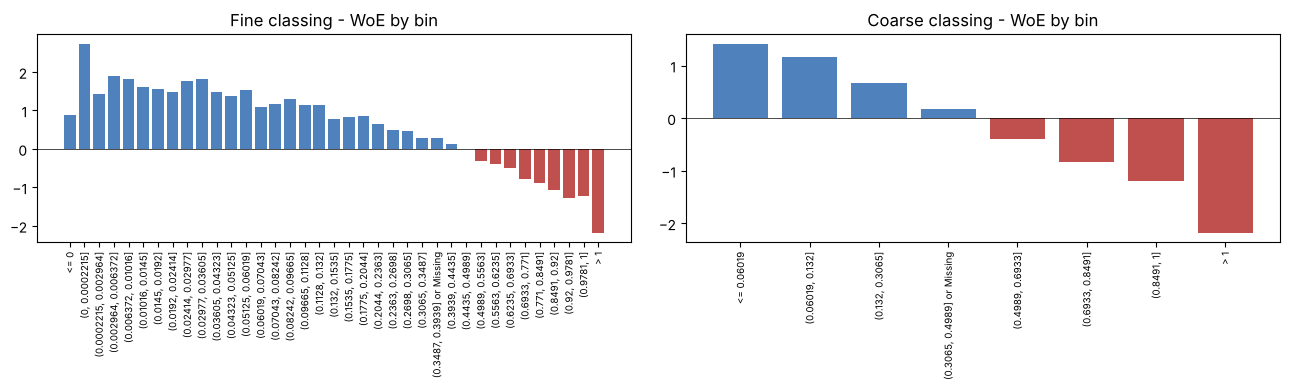

In [3]:
fine = WoEBinner("revolving_util", trend="free", min_share=0, min_bad=0, min_woe_gap=0, max_bins=40).fit(dev["revolving_util"], y)
coarse = WoEBinner("revolving_util", trend="increasing_risk", min_share=0.02).fit(dev["revolving_util"], y)
print("fine bins:", len(fine.woe_), "| coarse bins:", len(coarse.woe_))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, b, title in [(ax[0], fine, "Fine classing"), (ax[1], coarse, "Coarse classing")]:
    t = b.table_[b.table_["bin"] != "Missing"]
    a.bar(range(len(t)), t["woe"], color=np.where(t["woe"] < 0, "#c0504d", "#4f81bd"))
    a.set_xticks(range(len(t))); a.set_xticklabels(t["bin"], rotation=90, fontsize=7)
    a.set_title(f"{title} - WoE by bin"); a.axhline(0, color="k", lw=0.5)
plt.tight_layout(); plt.savefig("../outputs/figures/fine_vs_coarse_revolving_util.png", dpi=130); plt.show()

**Reading:** fine bins are noisy at the edges and unnecessarily many; the coarse version keeps the monotonic shape and the important
over-limit bin (> 1) with a handful of bins that a credit officer can read.

## 3. Fit all variables on the development set

In [4]:
binners = {}
for var, (trend, share, _) in CONFIG.items():
    binners[var] = WoEBinner(var, trend=trend, min_share=share).fit(dev[var], y)

tables = pd.concat([b.table_ for b in binners.values()], ignore_index=True)

# programmatic checks of the rules
for var, b in binners.items():
    trend = CONFIG[var][0]
    if trend == "increasing_risk":
        assert np.all(np.diff(b.woe_) < 0), var
    elif trend == "decreasing_risk":
        assert np.all(np.diff(b.woe_) > 0), var
    assert (b.table_["bad"] >= 30).all(), var
    assert b.table_["rows"].sum() == len(dev), var
print("OK: monotonicity, bad-count and row-total checks passed for all variables")

OK: monotonicity, bad-count and row-total checks passed for all variables


In [5]:
for var, b in binners.items():
    print(f"\n{var}  (IV = {b.iv_:.4f}, {iv_strength(b.iv_)}; NaN handling: {b.missing_mode_})")
    display(b.table_.drop(columns=["variable", "good"]).round(4))


revolving_util  (IV = 1.1566, very strong (check for leakage); NaN handling: merged)


,bin,rows,pct_rows,bad,bad_rate,woe,iv_contrib
0,<= 0.06019,36684,0.3494,629,0.0171,1.4128,0.3934
1,"(0.06019, 0.132]",13102,0.1248,285,0.0218,1.1702,0.1056
2,"(0.132, 0.3065]",15721,0.1497,556,0.0354,0.6701,0.0507
3,"(0.3065, 0.4989] or Missing",10656,0.1015,609,0.0572,0.1673,0.0026
4,"(0.4989, 0.6933]",7861,0.0749,759,0.0966,-0.3997,0.0142
5,"(0.6933, 0.8491]",5241,0.0499,741,0.1414,-0.8320,0.0496
6,"(0.8491, 1]",13563,0.1292,2606,0.1921,-1.1997,0.3112
7,> 1,2159,0.0206,835,0.3868,-2.1749,0.2293



age  (IV = 0.2699, medium; NaN handling: none)


,bin,rows,pct_rows,bad,bad_rate,woe,iv_contrib
0,21-29,6125,0.0583,716,0.1169,-0.6137,0.0287
1,30-36,10569,0.1007,1115,0.1055,-0.4983,0.0311
2,37-43,14309,0.1363,1331,0.0930,-0.3585,0.0205
3,44-54,28026,0.2669,2179,0.0777,-0.1625,0.0076
4,55-57,7254,0.0691,416,0.0573,0.1637,0.0017
5,58-62,12031,0.1146,553,0.0460,0.3970,0.0152
6,63-66,8374,0.0798,289,0.0345,0.6955,0.0288
7,67+,18299,0.1743,421,0.0230,1.1128,0.1363



n_30_59_late  (IV = 0.7359, very strong (check for leakage); NaN handling: own_bin)


...

,bin,rows,pct_rows,bad,bad_rate,woe,iv_contrib
0,0-1,4397,0.0419,762,0.1733,-1.0734,0.0767
1,2,4738,0.0451,439,0.0927,-0.3542,0.0066
2,3,6327,0.0603,499,0.0789,-0.1780,0.0021
3,4-5,17070,0.1626,1082,0.0634,0.0572,0.0005
4,6+,72455,0.6901,4238,0.0585,0.1427,0.0132



n_real_estate  (IV = 0.0618, weak; NaN handling: none)


,bin,rows,pct_rows,bad,bad_rate,woe,iv_contrib
0,0,39425,0.3755,3289,0.0834,-0.2392,0.0238
1,1,36618,0.3488,1919,0.0524,0.2590,0.0209
2,2,21975,0.2093,1240,0.0564,0.1808,0.0063
3,3,4431,0.0422,283,0.0639,0.0491,0.0001
4,4+,2538,0.0242,289,0.1139,-0.5841,0.0106



n_dependents  (IV = 0.0389, weak; NaN handling: own_bin)


,bin,rows,pct_rows,bad,bad_rate,woe,iv_contrib
0,0,60916,0.5802,3539,0.0581,0.1499,0.0122
1,1,18454,0.1758,1390,0.0753,-0.1282,0.0031
2,2,13557,0.1291,1093,0.0806,-0.2019,0.0057
3,3,6624,0.0631,599,0.0904,-0.3275,0.0078
4,4+,2713,0.0258,275,0.1014,-0.4537,0.0065
5,Missing,2723,0.0259,124,0.0455,0.4067,0.0036


**Reading the tables**
- `revolving_util`: bad rate climbs from under 2% at low utilization to 39% above 100%. Its NaN group (175 rows, only 9 bad cases) is too small to estimate its own WoE, so it joins the closest numeric bin, labelled `(0.3065, 0.4989] or Missing`.
- Late-count variables: separate bins for 0, 1 and 2+ delinquencies (`n_30_59_late` also splits out 3+), plus the **Missing** bin, which is really the "special code 96/98" group (59% bad).
- `monthly_income` and `debt_ratio` share an identical Missing bin (22,424 rows, 5.3% bad), because they are `NaN` on the same rows.
- `n_real_estate` is intentionally **not** monotonic: customers with 0 real-estate loans are riskier than those with 1-2, and risk rises again at 4+.

## 4. Information Value ranking

In [6]:
iv = iv_summary(binners)
iv

,variable,iv,strength,n_bins,missing_handling
0,revolving_util,1.156586,very strong (check for leakage),8,merged
1,n_90_late,0.883762,very strong (check for leakage),4,own_bin
2,n_30_59_late,0.735913,very strong (check for leakage),5,own_bin
3,n_60_89_late,0.590217,very strong (check for leakage),4,own_bin
4,age,0.269891,medium,8,none
5,n_open_lines,0.099101,weak,5,none
6,monthly_income,0.082434,weak,8,own_bin
7,debt_ratio,0.079622,weak,6,own_bin
8,n_real_estate,0.061841,weak,5,none
9,n_dependents,0.038921,weak,6,own_bin


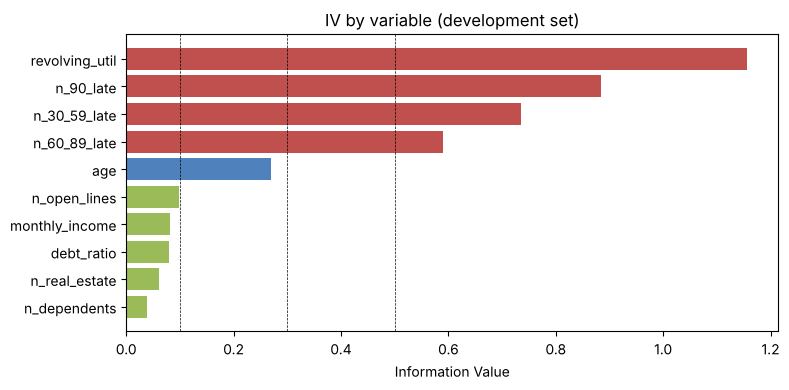

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
col = {"useless": "#bbbbbb", "weak": "#9bbb59", "medium": "#4f81bd", "strong": "#f79646", "very strong (check for leakage)": "#c0504d"}
ax.barh(iv["variable"][::-1], iv["iv"][::-1], color=[col[s] for s in iv["strength"][::-1]])
for x_, label in [(0.1, "0.1"), (0.3, "0.3"), (0.5, "0.5")]:
    ax.axvline(x_, color="k", lw=0.5, ls="--")
ax.set_xlabel("Information Value"); ax.set_title("IV by variable (development set)")
plt.tight_layout(); plt.savefig("../outputs/figures/iv_ranking.png", dpi=130); plt.show()

**Reading:** four variables sit above the 0.5 "suspicious" line: `revolving_util` (~1.16) and the three delinquency counts (0.59-0.88).
This is **not** evidence of leakage in itself: these are credit-bureau behaviour variables recorded at the observation date, and they are
known to be extremely predictive for this dataset. But it is a flag to remember, because the dataset has no dates and we cannot verify the
timing of each field. The safeguard is the validation notebook: if hold-out AUC came out near 0.95 we would suspect leakage; a value around 0.85-0.86 is the normal range for this data.

Also note that the three delinquency counts are related to each other (and share the same Missing group), so we will not keep all of them blindly. That is decided in notebook 05 using correlation, VIF and coefficient signs.

## 5. WoE profiles

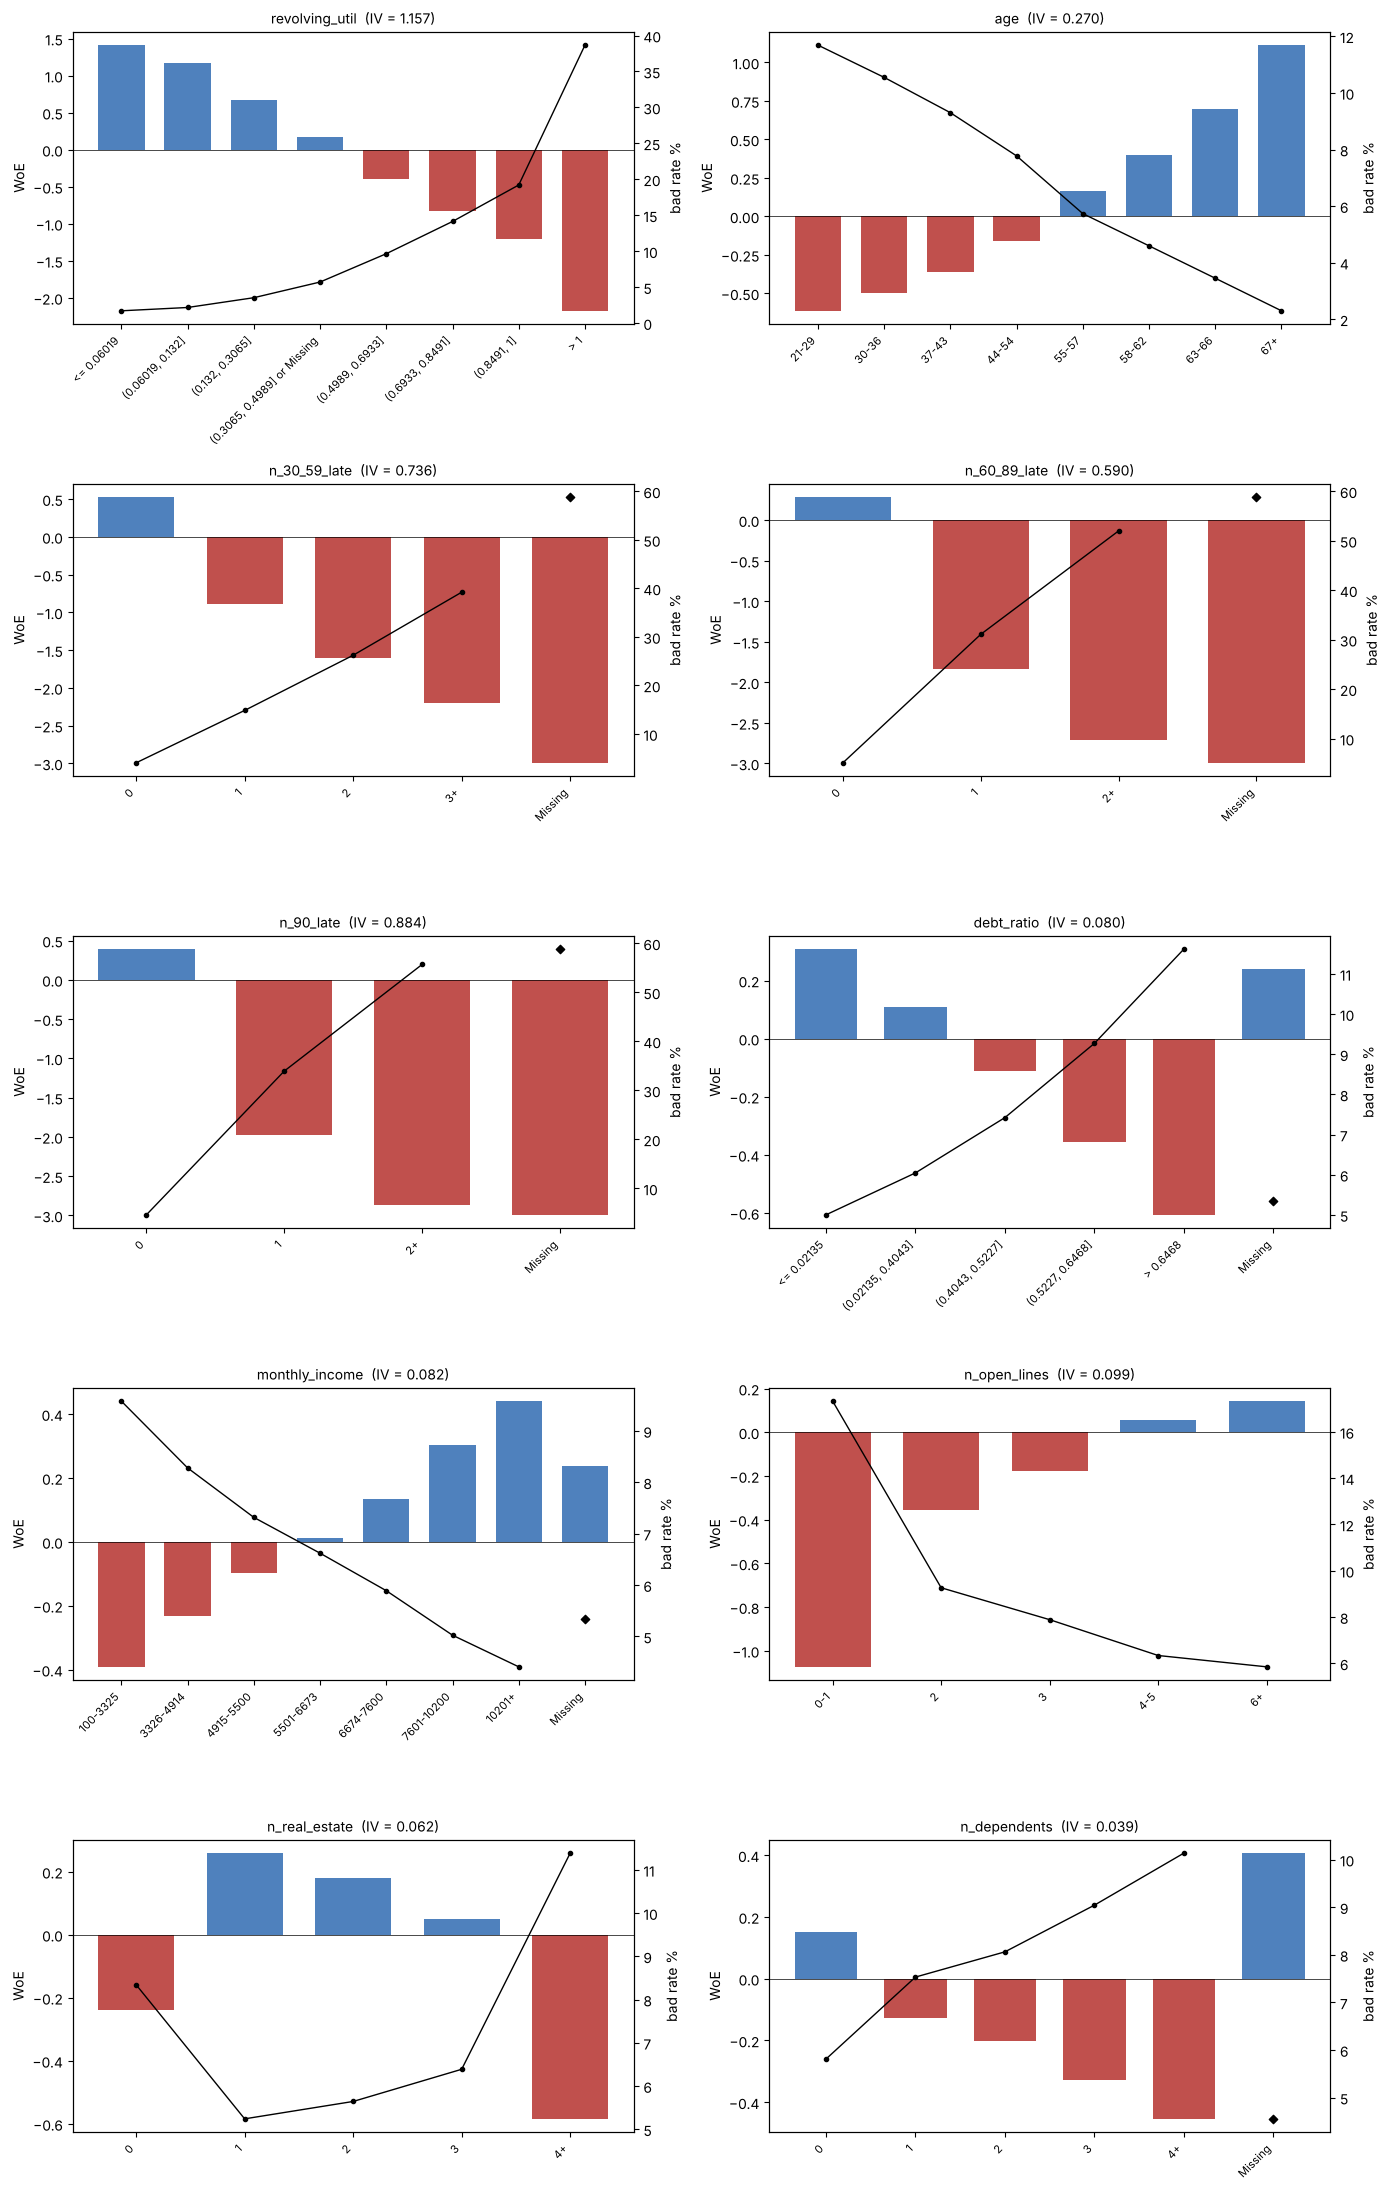

In [8]:
fig, axes = plt.subplots(5, 2, figsize=(14, 22))
for a, (var, b) in zip(axes.ravel(), binners.items()):
    t = b.table_
    a.bar(range(len(t)), t["woe"], color=np.where(t["woe"] < 0, "#c0504d", "#4f81bd"), width=0.7)
    a.axhline(0, color="k", lw=0.5)
    a.set_xticks(range(len(t))); a.set_xticklabels(t["bin"], rotation=45, ha="right", fontsize=8)
    a.set_ylabel("WoE"); a.set_title(f"{var}  (IV = {b.iv_:.3f})", fontsize=10)
    num = t["bin"] != "Missing"                      # draw the line over ordered bins only
    a2 = a.twinx(); a2.plot(np.arange(len(t))[num], t.loc[num, "bad_rate"] * 100, color="k", marker="o", ms=3, lw=1)
    if (~num).any():
        a2.scatter(np.arange(len(t))[~num], t.loc[~num, "bad_rate"] * 100, color="k", marker="D", s=18)
    a2.set_ylabel("bad rate %")
plt.tight_layout(); plt.savefig("../outputs/figures/woe_profiles.png", dpi=110); plt.show()

## 6. Hand calculation (do this yourself too)

Recompute one bin **independently from raw counts** and compare with the function. Bin: `n_30_59_late == 1`.

In [9]:
G, B = int((y == 0).sum()), int((y == 1).sum())
mask = dev["n_30_59_late"] == 1
good_i, bad_i = int((mask & (y == 0)).sum()), int((mask & (y == 1)).sum())
pct_good, pct_bad = good_i / G, bad_i / B
woe_manual = np.log(pct_good / pct_bad)
iv_manual = (pct_good - pct_bad) * woe_manual

row = binners["n_30_59_late"].table_.query("bin == '1'").iloc[0]
print(f"totals: good = {G:,}, bad = {B:,}")
print(f"bin '1': good = {good_i:,}, bad = {bad_i:,} -> %good = {pct_good:.4%}, %bad = {pct_bad:.4%}")
print(f"WoE  manual = {woe_manual:.4f} | function = {row.woe:.4f}")
print(f"IV contribution  manual = {iv_manual:.4f} | function = {row.iv_contrib:.4f}")
assert np.isclose(woe_manual, row.woe) and np.isclose(iv_manual, row.iv_contrib)

totals: good = 97,967, bad = 7,020
bin '1': good = 9,543, bad = 1,665 -> %good = 9.7410%, %bad = 23.7179%
WoE  manual = -0.8899 | function = -0.8899
IV contribution  manual = 0.1244 | function = 0.1244


## 7. Stability check inside the development set

The hold-out stays closed, so we check stability by splitting the **development** set into two random halves and recomputing the WoE of the same bins in each half.
Large differences would mean the bins are driven by noise.

In [10]:
rng = np.random.default_rng(42)
half = pd.Series(rng.random(len(dev)) < 0.5, index=dev.index)

def woe_by_bin(binner, x, y_):
    idx = binner.bin_index(x)
    ct = pd.crosstab(idx, y_).reindex(range(len(binner.table_)), fill_value=0)
    good, bad = ct[0].to_numpy() + 0.5, ct[1].to_numpy() + 0.5
    return np.log((good / good.sum()) / (bad / bad.sum()))

rows = []
for var, b in binners.items():
    w1 = woe_by_bin(b, dev.loc[half, var], y[half])
    w2 = woe_by_bin(b, dev.loc[~half, var], y[~half])
    trend = CONFIG[var][0]
    if trend == "free":
        mono = "n/a"
    else:
        sign = 1 if trend == "decreasing_risk" else -1
        nm = len(b.woe_)  # numeric bins only
        mono = bool(np.all(sign * np.diff(w1[:nm]) > 0) and np.all(sign * np.diff(w2[:nm]) > 0))
    rows.append({"variable": var, "max_abs_woe_diff": np.abs(w1 - w2).max(), "monotone_in_both_halves": mono})
stab = pd.DataFrame(rows).round(3)
stab

,variable,max_abs_woe_diff,monotone_in_both_halves
0,revolving_util,0.218,True
1,age,0.134,True
2,n_30_59_late,0.278,True
3,n_60_89_late,0.278,True
4,n_90_late,0.278,True
5,debt_ratio,0.099,True
6,monthly_income,0.184,False
7,n_open_lines,0.137,True
8,n_real_estate,0.197,n/a
9,n_dependents,0.164,True


**Reading:** a small maximum WoE difference between the two halves means the bin estimates are stable. Most variables differ by less than 0.25. The three delinquency variables show 0.28 because their
shared Missing bin has only 170 rows, so its WoE is naturally noisier. `monthly_income` is the only variable whose monotonic order is not preserved in both halves: its middle bins (4915-5500 and 5501-6673) have almost the same WoE (-0.10 and +0.01),
so the monotonic shape there is not strongly supported by the data. We keep this in mind when interpreting coefficients; income has a weak IV anyway.

## 8. Save the binning specification

In [11]:
spec = {var: b.to_dict() for var, b in binners.items()}
with open("../outputs/scorecard/binning_spec.json", "w") as f:
    json.dump(spec, f, indent=2)
tables.to_csv("../outputs/scorecard/woe_bin_tables.csv", index=False)
iv.to_csv("../outputs/metrics/iv_summary.csv", index=False)

# the saved spec must reproduce the same WoE values on the development set
reloaded = {v: WoEBinner.from_dict(d) for v, d in spec.items()}
for var in CONFIG:
    assert np.allclose(reloaded[var].transform(dev[var]), binners[var].transform(dev[var])), var
print("Saved binning_spec.json, woe_bin_tables.csv, iv_summary.csv and figures; reload check passed")

Saved binning_spec.json, woe_bin_tables.csv, iv_summary.csv and figures; reload check passed


## Summary

- 10 variables binned on the development set with monotonic (business-driven) WoE, minimum bin sizes, and `NaN` kept as its own bin or merged when too small.
- IV ranking: `revolving_util` > `n_90_late` > `n_30_59_late` > `n_60_89_late` > `age`, then weak variables (`n_open_lines`, `monthly_income`, `debt_ratio`, `n_real_estate`, `n_dependents`).
- The saved `binning_spec.json` is applied unchanged to the hold-out set later.

**Questions to answer in your own words (interview material)**
1. Why do we force WoE to be monotonic, and when did we deliberately not do it (`n_real_estate`)?
2. Why is it acceptable that IV is above 0.5 for `revolving_util`, and what would make you suspect leakage?
3. What would go wrong if we computed bins on the full dataset before splitting?

Next: notebook 05 - variable selection (IV, correlation, VIF) and the logistic regression on WoE variables.